# Homework 2: Learning from Both Sides

**Course:** NLP Fall 2026  
**Designer:** Ali Torkashvand

**Name:** Negin Moradi  

`The [MASK] was barking behind the door.`  
`The [MASK] was meowing behind the door.`

The missing word comes before the clue. A next-token model has read only `The`; a masked model can also read what follows.

Train two small Transformers on the same stories, then compare their continuations and word predictions. The blocks and training loop are supplied. Complete five functions for preparing targets, controlling context, and making predictions.

## 1. Set up the experiment

Enable a Kaggle GPU and Internet, then run the cells in order. Use `SMOKE` to check your code and `FULL` for the experiments. Training prints a time estimate after 100 updates and saves checkpoints in `pretraining_runs`; interrupted runs resume automatically.

In [1]:
%pip -q install "datasets>=3.0,<5" "tokenizers>=0.20,<1" "matplotlib>=3.8,<4" "pandas>=2.2,<3"

Note: you may need to restart the kernel to use updated packages.


In [2]:
import copy
import hashlib
import json
import math
import random
import re
import time
import textwrap
from contextlib import nullcontext
from pathlib import Path

import datasets
import matplotlib.pyplot as plt
import pandas as pd
import tokenizers
import torch
from datasets import load_dataset
from IPython.display import display
from tokenizers import Tokenizer, models, trainers, pre_tokenizers, decoders
from torch import nn
from torch.nn import functional as F

if tuple(int(v) for v in torch.__version__.split('+')[0].split('.')[:2]) < (2, 3):
    raise RuntimeError('Use a recent Kaggle image with PyTorch 2.3 or later.')

SEED = 42
MODE = 'FULL'  # Change to 'SMOKE' for a short pipeline check.
assert MODE in {'FULL', 'SMOKE'}
CFG = dict(train_stories=100_000, eval_stories=3_000, vocab_size=8192,
           length=128, width=256, layers=6, heads=4, dropout=0.1,
           batch_size=32, accumulation=2, steps=12000, lr=6e-4,
           eval_every=500, eval_blocks=256, puzzle_count=500)
if MODE == 'SMOKE':
    CFG.update(train_stories=2000, eval_stories=300, steps=30,
               eval_every=15, eval_blocks=32, puzzle_count=40)

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
WORK = Path('/kaggle/working') if Path('/kaggle/working').exists() else Path.cwd()
RUNS = WORK / 'pretraining_runs'
RUNS.mkdir(exist_ok=True)
torch.manual_seed(SEED)
random.seed(SEED)
if DEVICE.type == 'cuda':
    torch.cuda.manual_seed_all(SEED)
    torch.set_float32_matmul_precision('high')
    print('GPU:', torch.cuda.get_device_name())
elif MODE == 'FULL':
    raise RuntimeError('FULL requires a GPU. Enable one, or select SMOKE to check the code.')
print('Mode:', MODE, '| device:', DEVICE)
display(pd.Series(CFG, name='Setting').to_frame())

GPU: Tesla T4
Mode: FULL | device: cuda


,Setting
train_stories,100000.0000
eval_stories,3000.0000
vocab_size,8192.0000
length,128.0000
width,256.0000
layers,6.0000
heads,4.0000
dropout,0.1000
batch_size,32.0000
accumulation,2.0000


## 2. Meet the stories

TinyStories contains synthetic children's stories with simple vocabulary and recurring situations. We sample 100,000 training stories and use separate stories for validation and testing. Exact copies cannot cross these splits. Both models receive the same training examples.

In [3]:
def fingerprint(text):
    return hashlib.sha256(' '.join(text.split()).encode()).hexdigest()

def take_unique(stream, count, excluded=None):
    seen = set() if excluded is None else set(excluded)
    texts = []
    for row in stream:
        text = row['text'].strip()
        key = fingerprint(text)
        if text and key not in seen:
            texts.append(text)
            seen.add(key)
        if len(texts) == count:
            return texts
    raise ValueError(f'Only found {len(texts)} of {count} requested stories.')

data_dir = RUNS / f'data_{CFG["train_stories"]}_{CFG["eval_stories"]}_{SEED}'
data_dir.mkdir(exist_ok=True)
data_file = data_dir / 'stories.json'
if data_file.exists():
    corpus = json.loads(data_file.read_text(encoding='utf-8'))
else:
    heldout_stream = load_dataset('roneneldan/TinyStories', split='validation', streaming=True)
    heldout = take_unique(heldout_stream.shuffle(seed=SEED, buffer_size=10_000),
                          CFG['eval_stories'])
    n_valid = len(heldout) // 2
    train_stream = load_dataset('roneneldan/TinyStories', split='train', streaming=True)
    train_texts = take_unique(train_stream.shuffle(seed=SEED, buffer_size=10_000),
                              CFG['train_stories'], {fingerprint(t) for t in heldout})
    corpus = dict(train=train_texts, validation=heldout[:n_valid], test=heldout[n_valid:])
    data_file.write_text(json.dumps(corpus, ensure_ascii=False), encoding='utf-8')

split_keys = {s: {fingerprint(t) for t in texts} for s, texts in corpus.items()}
assert not (split_keys['train'] & (split_keys['validation'] | split_keys['test']))
assert not (split_keys['validation'] & split_keys['test'])
display(pd.DataFrame([(s, len(t)) for s, t in corpus.items()], columns=['Split', 'Stories']))
print(corpus['train'][0][:700])

README.md:   0%|          | 0.00/1.06k [00:00<?, ?B/s]

,Split,Stories
0,train,100000
1,validation,1500
2,test,1500


Anna and Ben were going on a trip with their mom and dad. They were very excited to see new things and have fun. They packed their luggage with their clothes, toys and books. Anna had a furry teddy bear that she loved very much. She put it in her backpack and hugged it.

"Are you ready to go?" Mom asked. "Yes, we are!" Anna and Ben said. They got in the car and drove to the airport. They had to wait in a long line to check in their luggage. Anna and Ben were bored and started to run around and make noise.

"Anna, Ben, behave!" Dad said. "You have to be quiet and stay with us. There are many people here and we don't want to lose you." Anna and Ben nodded, but they did not listen. They saw a b


## 3. One vocabulary for both models

We train an 8,192-token byte-level BPE tokenizer on the training stories. A token may be a word, part of a word, or punctuation. Both models share this vocabulary.

Each story starts with `<bos>` and ends with `<eos>`. Long stories become separate windows with one overlapping boundary token; short windows are padded. No window joins two stories. Padding is excluded from attention keys and loss.

In [4]:
tokenizer_file = data_dir / f'bpe_{CFG["vocab_size"]}.json'
if tokenizer_file.exists():
    tokenizer = Tokenizer.from_file(str(tokenizer_file))
else:
    tokenizer = Tokenizer(models.BPE(unk_token='<unk>'))
    tokenizer.pre_tokenizer = pre_tokenizers.ByteLevel(add_prefix_space=False)
    tokenizer.decoder = decoders.ByteLevel()
    trainer = trainers.BpeTrainer(
        vocab_size=CFG['vocab_size'], min_frequency=2,
        special_tokens=['<pad>', '<bos>', '<eos>', '[MASK]', '<unk>'],
        initial_alphabet=pre_tokenizers.ByteLevel.alphabet())
    tokenizer.train_from_iterator(corpus['train'], trainer=trainer,
                                  length=len(corpus['train']))
    tokenizer.save(str(tokenizer_file))

PAD, BOS, EOS, MASK, UNK = [tokenizer.token_to_id(t) for t in
                           ['<pad>', '<bos>', '<eos>', '[MASK]', '<unk>']]
SPECIAL = {PAD, BOS, EOS, MASK, UNK}
V = tokenizer.get_vocab_size()
REGULAR = torch.tensor([i for i in range(V) if i not in SPECIAL])

def encode(text):
    return tokenizer.encode(text).ids

def decode(ids):
    return tokenizer.decode([int(i) for i in ids], skip_special_tokens=True)

def make_windows(texts):
    length = CFG['length']
    windows = []
    for start in range(0, len(texts), 512):
        for enc in tokenizer.encode_batch(texts[start:start + 512]):
            ids = [BOS, *enc.ids, EOS]
            for j in range(0, len(ids) - 1, length):
                row = ids[j:j + length + 1]
                windows.append(row + [PAD] * (length + 1 - len(row)))
    return torch.tensor(windows, dtype=torch.long)

train_windows = make_windows(corpus['train'])
valid_windows_all = make_windows(corpus['validation'])
selection = torch.randperm(len(valid_windows_all), generator=torch.Generator().manual_seed(SEED))
valid_windows = valid_windows_all[selection[:CFG['eval_blocks']]]
del valid_windows_all
display(pd.DataFrame({'Token': [repr(tokenizer.id_to_token(i)) for i in encode('The dog was barking.')],
                      'ID': encode('The dog was barking.')}))
print('Vocabulary:', V, '| training windows:', len(train_windows))
print('Non-padding source tokens:', int((train_windows[:, :-1] != PAD).sum()))

,Token,ID
0,'The',376
1,'Ġdog',647
2,'Ġwas',286
3,'Ġbarking',4048
4,'.',18


Vocabulary: 8192 | training windows: 226833
Non-padding source tokens: 22230988


## 4. Predict one token ahead

The autoregressive model reads positions `0...T-1` and predicts positions `1...T`. For `<bos> The dog`, its targets are `The dog ...`. During training, it receives the correct earlier tokens: **teacher forcing**.

**TODO 1:** From windows of shape `[B, T+1]`, return inputs and labels of shape `[B, T]`, shifted by one token. Replace padding labels with `-100`, which cross-entropy ignores. Keep the original windows unchanged.

In [5]:
def autoregressive_batch(windows):
    """Return shifted inputs and labels [B, T] from windows [B, T+1]."""
    inputs = windows[:, :-1].clone() # the model sees each token except the final one... (select everything except the last column)
    labels = windows[:, 1:].clone() # ...and is trained to predict the following token (select everything except the first column)
    labels[labels == PAD] = -100 # padding labels
    return inputs, labels

In [6]:
sample = torch.tensor([[BOS, 7, 8, EOS, PAD]])
saved_sample = sample.clone()
inputs, labels = autoregressive_batch(sample)
assert torch.equal(inputs, torch.tensor([[BOS, 7, 8, EOS]]))
assert torch.equal(labels, torch.tensor([[7, 8, EOS, -100]]))
assert torch.equal(sample, saved_sample)

In [7]:
demo = torch.tensor([[BOS, *encode('The dog was barking.'), EOS]])
x_demo, y_demo = autoregressive_batch(demo)
display(pd.DataFrame({'Input': [tokenizer.id_to_token(i) for i in x_demo[0].tolist()],
                      'Target': [tokenizer.id_to_token(i) for i in y_demo[0].tolist()]}))
assert torch.equal(x_demo[:, 1:], y_demo[:, :-1])

,Input,Target
0,<bos>,The
1,The,Ġdog
2,Ġdog,Ġwas
3,Ġwas,Ġbarking
4,Ġbarking,.
5,.,<eos>


## 5. Recover hidden tokens

The masked model predicts tokens at their original positions. We select about 15% of ordinary tokens; special tokens are excluded. Of the selected tokens, 80% become `[MASK]`, 10% become a random ordinary token, and 10% stay unchanged. All selected positions contribute to the loss, including those left unchanged.

**TODO 2:** Selection is supplied. Build corrupted inputs and labels: keep the original targets at selected positions and set all other labels to `-100`. Use the supplied generator for random draws and `REGULAR` for replacement tokens. Masks change during training; validation corruption stays fixed.

In [8]:
def masked_batch(windows, generator, probability=0.15):
    """Corrupt selected tokens; return inputs and labels [B, T]."""
    original = windows[:, :-1].clone()
    eligible = torch.ones_like(original, dtype=torch.bool)
    for token in SPECIAL:
        eligible &= original != token
    selected = (torch.rand(original.shape, generator=generator) < probability) & eligible
    # Ensure each usable row has at least one target, including short final windows.
    for row in range(len(original)):
        if eligible[row].any() and not selected[row].any():
            candidates = eligible[row].nonzero(as_tuple=True)[0]
            j = torch.randint(len(candidates), (1,), generator=generator).item()
            selected[row, candidates[j]] = True
            
    corrupted = original.clone() # keeping a copy of the original tokens as the input to be corrupted
    draws = torch.rand(original.shape, generator=generator)
    mask_positions = selected & (draws < 0.8) # selected tokens that will become MASK
    random_positions = selected & (draws >= 0.8) & (draws < 0.9) # selected tokens that will become random ordinary tokens

    corrupted[mask_positions] = MASK
    
    number_random = int(random_positions.sum().item()) # replace 10% with random ordinary tokens
    if number_random:
        random_ids = torch.randint(len(REGULAR), (number_random,), generator=generator)
        corrupted[random_positions] = REGULAR[random_ids]

    # only selected positions contribute to the prediction loss
    labels = torch.full_like(original, -100)
    labels[selected] = original[selected]
    return corrupted, labels

In [9]:
sample = torch.tensor([[BOS, 7, 8, EOS, PAD]])
saved_sample = sample.clone()
inputs, labels = masked_batch(sample, torch.Generator().manual_seed(3), probability=1.0)
assert inputs.shape == labels.shape == (1, 4)
assert torch.equal(labels, torch.tensor([[-100, 7, 8, -100]]))
assert inputs[0, 0] == BOS and inputs[0, -1] == EOS
assert torch.equal(sample, saved_sample)

In [10]:
masked_demo, masked_labels = masked_batch(demo, torch.Generator().manual_seed(7), probability=0.5)
display(pd.DataFrame({'Original': [tokenizer.id_to_token(i) for i in demo[0, :-1].tolist()],
                      'Visible input': [tokenizer.id_to_token(i) for i in masked_demo[0].tolist()],
                      'Scored target': ['—' if i == -100 else tokenizer.id_to_token(i)
                                        for i in masked_labels[0].tolist()]}))
assert (masked_labels != -100).any()
assert not torch.isin(masked_labels[masked_labels != -100], torch.tensor(sorted(SPECIAL))).any()

,Original,Visible input,Scored target
0,<bos>,<bos>,—
1,The,[MASK],The
2,Ġdog,Ġdog,—
3,Ġwas,Ġwas,—
4,Ġbarking,Thomas,Ġbarking
5,.,[MASK],.


## 6. Which positions can each model read?

Both models use the supplied Transformer. Autoregressive attention reads the current and earlier positions; masked attention reads both sides. The attention mask controls what is visible. The loss labels control which predictions are scored.

**TODO 3:** Return a boolean `[T, T]` visibility matrix. Rows are queries, columns are keys, and `True` means visible. Include the diagonal for causal attention; allow every position for bidirectional attention. Padding is handled separately.

In [11]:
def visible_positions(length, causal):
    """Return [T, T], with True for a visible key at each query."""
    if causal:
        return torch.tril(torch.ones((length, length), dtype=torch.bool)) # query position i can see keys 0 through i, including itself
    return torch.ones((length, length), dtype=torch.bool) # bidirectional attention allows every query to see every key

In [12]:
assert torch.equal(visible_positions(3, True), torch.tensor([
    [True, False, False], [True, True, False], [True, True, True]]))
assert visible_positions(3, False).dtype == torch.bool
assert visible_positions(3, False).all()

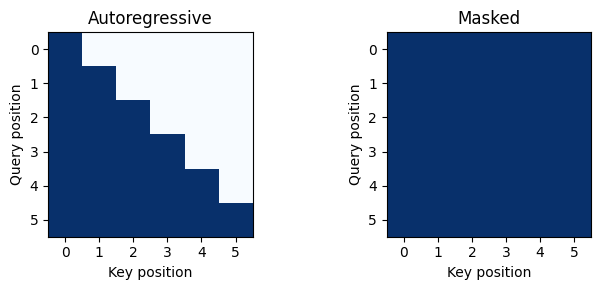

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(7, 3))
for ax, causal, title in zip(axes, [True, False], ['Autoregressive', 'Masked']):
    ax.imshow(visible_positions(6, causal), vmin=0, vmax=1, cmap='Blues')
    ax.set(title=title, xlabel='Key position', ylabel='Query position',
           xticks=range(6), yticks=range(6))
plt.tight_layout()
plt.show()

In [14]:
class Attention(nn.Module):
    def __init__(self, width, heads, dropout):
        super().__init__()
        self.heads, self.dropout = heads, dropout
        self.qkv = nn.Linear(width, 3 * width)
        self.out = nn.Linear(width, width)

    def forward(self, x, key_visible, causal):
        b, t, c = x.shape
        qkv = self.qkv(x).view(b, t, 3, self.heads, c // self.heads)
        q, k, v = qkv.permute(2, 0, 3, 1, 4).unbind(0)
        allowed = key_visible[:, None, None, :]
        if causal:
            allowed = allowed & visible_positions(t, True).to(x.device)[None, None]
        out = F.scaled_dot_product_attention(q, k, v, attn_mask=allowed,
                     dropout_p=self.dropout if self.training else 0.0)
        return self.out(out.transpose(1, 2).contiguous().view(b, t, c))

class Block(nn.Module):
    def __init__(self, width, heads, dropout):
        super().__init__()
        self.norm1, self.norm2 = nn.LayerNorm(width), nn.LayerNorm(width)
        self.attn = Attention(width, heads, dropout)
        self.ff = nn.Sequential(nn.Linear(width, 4 * width), nn.GELU(),
                                nn.Linear(4 * width, width))
        self.drop = nn.Dropout(dropout)

    def forward(self, x, visible, causal):
        x = x + self.drop(self.attn(self.norm1(x), visible, causal))
        return x + self.drop(self.ff(self.norm2(x)))

class LanguageModel(nn.Module):
    def __init__(self, causal):
        super().__init__()
        self.causal = causal
        w = CFG['width']
        self.tokens = nn.Embedding(V, w)
        self.positions = nn.Embedding(CFG['length'], w)
        self.drop = nn.Dropout(CFG['dropout'])
        self.blocks = nn.ModuleList([Block(w, CFG['heads'], CFG['dropout'])
                                    for _ in range(CFG['layers'])])
        self.norm = nn.LayerNorm(w)
        self.output = nn.Linear(w, V, bias=False)
        self.apply(self.initialize)
        self.output.weight = self.tokens.weight

    @staticmethod
    def initialize(module):
        if isinstance(module, (nn.Linear, nn.Embedding)):
            nn.init.normal_(module.weight, std=0.02)
            if isinstance(module, nn.Linear) and module.bias is not None:
                nn.init.zeros_(module.bias)

    def forward(self, ids):
        assert ids.shape[1] <= CFG['length']
        visible = ids != PAD
        positions = torch.arange(ids.shape[1], device=ids.device)
        x = self.drop(self.tokens(ids) + self.positions(positions))
        for block in self.blocks:
            x = block(x, visible, self.causal)
        return self.output(self.norm(x))

torch.manual_seed(SEED)
initial_model = LanguageModel(causal=True)
initial_state = copy.deepcopy(initial_model.state_dict())
parameter_count = sum(p.numel() for p in initial_model.parameters())
print(f'Parameters per model: {parameter_count:,}')
del initial_model

Parameters per model: 6,868,992


### Check information flow

Change a later token and compare the earlier predictions. They must stay unchanged in the causal model. Bidirectional predictions can change, even before training.

In [15]:
check_ids = torch.tensor([[BOS, *encode('The dog was barking.')]])[:, :CFG['length']]
changed = check_ids.clone()
changed[0, -1] = REGULAR[(int(changed[0, -1]) + 17) % len(REGULAR)]
for causal in [True, False]:
    check = LanguageModel(causal).eval()
    check.load_state_dict(initial_state)
    with torch.no_grad():
        a, b = check(check_ids), check(changed)
    difference = (a[:, :-1] - b[:, :-1]).abs().max().item()
    if causal:
        assert torch.allclose(a[:, :-1], b[:, :-1], atol=1e-6)
    else:
        assert difference > 1e-7
    print(('Causal' if causal else 'Bidirectional'), '| earlier-logit change:', round(difference, 6))
del check

Causal | earlier-logit change: 0.0
Bidirectional | earlier-logit change: 0.623947


## 7. Train on the same stories

Both models start from identical weights and use the same batch order, optimizer, and update budget. The masked model scores selected tokens; the autoregressive model scores almost every token. Equal input exposure therefore gives different numbers of prediction targets.

The supplied loop trains each model and keeps its checkpoint with the lowest validation loss. The full run uses 12,000 updates per model, each with 64 windows processed in two batches of 32.

In [16]:
valid_ar = autoregressive_batch(valid_windows)
valid_mlm = masked_batch(valid_windows, torch.Generator().manual_seed(SEED + 1))
metadata = dict(config=CFG, seed=SEED, vocab=V,
                versions=dict(torch=torch.__version__, datasets=datasets.__version__,
                              tokenizers=tokenizers.__version__),
                tokenizer=hashlib.sha256(tokenizer.to_str().encode()).hexdigest(),
                train=hashlib.sha256(train_windows.numpy().tobytes()).hexdigest(),
                validation=hashlib.sha256(valid_windows.numpy().tobytes()).hexdigest(),
                test=hashlib.sha256(json.dumps(corpus['test']).encode()).hexdigest(),
                recipe='shared-transformer-80-10-10-v1')
run_id = hashlib.sha256(json.dumps(metadata, sort_keys=True).encode()).hexdigest()[:12]
run_dir = RUNS / f'{MODE.lower()}_{run_id}'
run_dir.mkdir(exist_ok=True)
(run_dir / 'settings.json').write_text(json.dumps(metadata, indent=2), encoding='utf-8')
tokenizer.save(str(run_dir / 'tokenizer.json'))
amp_dtype = (torch.bfloat16 if DEVICE.type == 'cuda' and torch.cuda.is_bf16_supported()
             else torch.float16)

def precision():
    return torch.autocast('cuda', dtype=amp_dtype) if DEVICE.type == 'cuda' else nullcontext()

@torch.no_grad()
def evaluate(model, prepared):
    model.eval()
    inputs, labels = prepared
    loss_sum, correct, count = 0.0, 0, 0
    for start in range(0, len(inputs), CFG['batch_size']):
        x = inputs[start:start + CFG['batch_size']].to(DEVICE)
        y = labels[start:start + CFG['batch_size']].to(DEVICE)
        with precision():
            logits = model(x)
        keep = y != -100
        loss_sum += F.cross_entropy(logits.float().flatten(0, 1), y.flatten(),
                                    ignore_index=-100, reduction='sum').item()
        correct += ((logits.argmax(-1) == y) & keep).sum().item()
        count += keep.sum().item()
    return dict(loss=loss_sum / count, accuracy=correct / count, targets=count)

def atomic_save(payload, path):
    temporary = path.with_suffix('.tmp')
    torch.save(payload, temporary)
    temporary.replace(path)

def train(objective):
    assert objective in {'ar', 'mlm'}
    best_path, last_path = run_dir / f'{objective}_best.pt', run_dir / f'{objective}_last.pt'
    log_path = run_dir / f'{objective}_history.json'
    if last_path.exists():
        saved = torch.load(last_path, map_location='cpu', weights_only=False)
        if saved['step'] == CFG['steps']:
            print(objective.upper(), ': loaded completed run')
            return saved['history']
    else:
        saved = None
    torch.manual_seed(SEED)
    if DEVICE.type == 'cuda':
        torch.cuda.manual_seed_all(SEED)
    model = LanguageModel(causal=objective == 'ar').to(DEVICE)
    model.load_state_dict(initial_state)
    optimizer = torch.optim.AdamW(model.parameters(), lr=CFG['lr'], weight_decay=0.01)
    scaler = torch.amp.GradScaler('cuda', enabled=DEVICE.type == 'cuda' and amp_dtype == torch.float16)
    data_rng = torch.Generator().manual_seed(SEED + 2)
    mask_rng = torch.Generator().manual_seed(SEED + 3)
    validation = valid_ar if objective == 'ar' else valid_mlm
    history, best, start_step, previous_seconds = [], float('inf'), 0, 0.0
    totals = dict(loss_sum=0.0, targets=0, input_tokens=0)
    if saved:
        model.load_state_dict(saved['model'])
        optimizer.load_state_dict(saved['optimizer'])
        scaler.load_state_dict(saved['scaler'])
        data_rng.set_state(saved['data_rng'])
        mask_rng.set_state(saved['mask_rng'])
        torch.set_rng_state(saved['torch_rng'])
        if DEVICE.type == 'cuda':
            torch.cuda.set_rng_state_all(saved['cuda_rng'])
        history, best, start_step = saved['history'], saved['best'], saved['step']
        previous_seconds, totals = saved['seconds'], saved['totals']
        print(objective.upper(), ': resuming update', start_step)
        del saved
    else:
        baseline = evaluate(model, validation)
        history.append(dict(step=0, validation_loss=baseline['loss'],
                             validation_accuracy=baseline['accuracy'], train_loss=None,
                             seconds=0, input_tokens=0, targets=0))
    if DEVICE.type == 'cuda':
        torch.cuda.synchronize()
    started = time.perf_counter()
    warmup = max(10, int(0.05 * CFG['steps']))
    for step in range(start_step + 1, CFG['steps'] + 1):
        model.train()
        factor = (step / warmup if step <= warmup else
                  0.1 + 0.9 * 0.5 * (1 + math.cos(math.pi * (step - warmup) /
                                                  max(1, CFG['steps'] - warmup))))
        for group in optimizer.param_groups:
            group['lr'] = CFG['lr'] * factor
        optimizer.zero_grad(set_to_none=True)
        indices = torch.randint(len(train_windows),
                    (CFG['batch_size'] * CFG['accumulation'],), generator=data_rng)
        windows = train_windows[indices]
        x, y = (autoregressive_batch(windows) if objective == 'ar'
                else masked_batch(windows, mask_rng))
        target_count = int((y != -100).sum())
        step_loss = 0.0
        for start in range(0, len(x), CFG['batch_size']):
            xb = x[start:start + CFG['batch_size']].to(DEVICE)
            yb = y[start:start + CFG['batch_size']].to(DEVICE)
            with precision():
                logits = model(xb)
                loss_sum = F.cross_entropy(logits.flatten(0, 1), yb.flatten(),
                                            ignore_index=-100, reduction='sum')
                loss = loss_sum / target_count
            scaler.scale(loss).backward()
            step_loss += loss_sum.item()
        scaler.unscale_(optimizer)
        nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        scaler.step(optimizer)
        scaler.update()
        totals['loss_sum'] += step_loss
        totals['targets'] += target_count
        totals['input_tokens'] += int((x != PAD).sum())
        if step == start_step + 100:
            if DEVICE.type == 'cuda':
                torch.cuda.synchronize()
            seconds_per_step = (time.perf_counter() - started) / 100
            print(f'{objective.upper()}: estimated remaining training '
                  f'{seconds_per_step * (CFG["steps"] - step) / 60:.1f} min; evaluation adds time')
        if step % CFG['eval_every'] == 0 or step == CFG['steps']:
            metrics = evaluate(model, validation)
            seconds = previous_seconds + time.perf_counter() - started
            record = dict(step=step, train_loss=totals['loss_sum'] / totals['targets'],
                          validation_loss=metrics['loss'], validation_accuracy=metrics['accuracy'],
                          seconds=seconds, input_tokens=totals['input_tokens'], targets=totals['targets'])
            history.append(record)
            if metrics['loss'] < best:
                best = metrics['loss']
                atomic_save(dict(model=model.state_dict(), step=step, validation=metrics), best_path)
            atomic_save(dict(model=model.state_dict(), optimizer=optimizer.state_dict(),
                        scaler=scaler.state_dict(), step=step, history=history, best=best,
                        seconds=seconds, totals=totals, data_rng=data_rng.get_state(),
                        mask_rng=mask_rng.get_state(), torch_rng=torch.get_rng_state(),
                        cuda_rng=torch.cuda.get_rng_state_all() if DEVICE.type == 'cuda' else []), last_path)
            log_path.write_text(json.dumps(history, indent=2), encoding='utf-8')
            print(f'{objective.upper()} update {step:4d}: train {record["train_loss"]:.3f}, '
                  f'validation {metrics["loss"]:.3f}, accuracy {metrics["accuracy"]:.1%}, '
                  f'time {seconds / 60:.1f} min')
    del model, optimizer, scaler
    if DEVICE.type == 'cuda':
        torch.cuda.empty_cache()
    return history

AR: estimated remaining training 33.7 min; evaluation adds time
AR update  500: train 5.151, validation 3.563, accuracy 34.4%, time 1.5 min
AR update 1000: train 4.193, validation 2.962, accuracy 40.6%, time 3.1 min
AR update 1500: train 3.745, validation 2.703, accuracy 43.7%, time 4.7 min
AR update 2000: train 3.470, validation 2.548, accuracy 45.2%, time 6.3 min
AR update 2500: train 3.279, validation 2.440, accuracy 46.9%, time 7.9 min
AR update 3000: train 3.138, validation 2.363, accuracy 47.9%, time 9.5 min
AR update 3500: train 3.027, validation 2.314, accuracy 48.4%, time 11.1 min
AR update 4000: train 2.936, validation 2.265, accuracy 49.2%, time 12.7 min
AR update 4500: train 2.860, validation 2.229, accuracy 49.9%, time 14.3 min
AR update 5000: train 2.797, validation 2.194, accuracy 50.1%, time 15.9 min
AR update 5500: train 2.742, validation 2.168, accuracy 50.3%, time 17.5 min
AR update 6000: train 2.693, validation 2.146, accuracy 51.0%, time 19.1 min
AR update 6500: tr

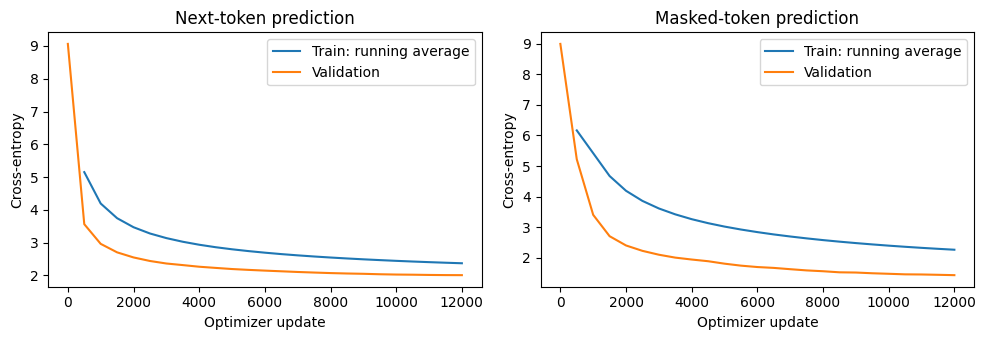

,Model,Parameters,Best update,Validation loss,Objective accuracy,Input tokens seen,Prediction targets seen,Training minutes
0,Autoregressive,6868992,12000,2.007,0.532,75270964,74934007,38.427
1,Masked,6868992,12000,1.433,0.679,75270964,11203852,38.165


In [17]:
ar_history = train('ar')
mlm_history = train('mlm')

fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
for ax, history, title in zip(axes, [ar_history, mlm_history],
                              ['Next-token prediction', 'Masked-token prediction']):
    frame = pd.DataFrame(history)
    ax.plot(frame.step, frame.train_loss, label='Train: running average')
    ax.plot(frame.step, frame.validation_loss, label='Validation')
    ax.set(title=title, xlabel='Optimizer update', ylabel='Cross-entropy')
    ax.legend()
plt.tight_layout()
plt.show()

def load_best(objective):
    checkpoint = torch.load(run_dir / f'{objective}_best.pt', map_location='cpu', weights_only=False)
    model = LanguageModel(causal=objective == 'ar').to(DEVICE)
    model.load_state_dict(checkpoint['model'])
    return model.eval(), checkpoint

ar_model, ar_checkpoint = load_best('ar')
mlm_model, mlm_checkpoint = load_best('mlm')
summary = []
for name, checkpoint, history in [('Autoregressive', ar_checkpoint, ar_history),
                                   ('Masked', mlm_checkpoint, mlm_history)]:
    summary.append({'Model': name, 'Parameters': parameter_count,
                    'Best update': checkpoint['step'], 'Validation loss': checkpoint['validation']['loss'],
                    'Objective accuracy': checkpoint['validation']['accuracy'],
                    'Input tokens seen': history[-1]['input_tokens'],
                    'Prediction targets seen': history[-1]['targets'],
                    'Training minutes': history[-1]['seconds'] / 60})
display(pd.DataFrame(summary).round(3))

Read each loss curve separately: the objectives score different tasks with different context. A lower masked-token loss does not establish a better model than a lower next-token loss. Only the next-token loss has the usual autoregressive perplexity interpretation.

## 8. Complete the ending

Generate with the autoregressive model by predicting a token, appending it, and repeating. It now reads its own predictions, so errors can accumulate.

**TODO 4:** Complete the generation loop. Pass at most the last `CFG['length']` tokens to the model and read its final-position logits. Exclude `PAD`, `BOS`, `MASK`, and `UNK`; sample from the top `top_k` logits after temperature scaling. Use `rng`, stop at `EOS`, and otherwise append the sampled token.

In [18]:
@torch.no_grad()
def generate(prompt, max_new_tokens=60, temperature=0.8, top_k=40, seed=10):
    """Sample a continuation from the autoregressive model."""
    if not prompt.strip():
        raise ValueError('Supply a story prefix.')
    if temperature <= 0 or top_k < 1:
        raise ValueError('Temperature and top_k must be positive.')
    ids = [BOS, *encode(prompt)]
    rng = torch.Generator(device=DEVICE).manual_seed(seed)
    ar_model.eval()
    for _ in range(max_new_tokens):
        context = torch.tensor(ids[-CFG['length']:], dtype=torch.long, device=DEVICE).unsqueeze(0) # only pass the most recent 128 tokens to the model
        logits = ar_model(context)[0, -1].float() # we only need the logits at the last position
        
        # never generate padding, a new beginning, a mask, or an unknown token.
        logits[PAD] = float('-inf')
        logits[BOS] = float('-inf')
        logits[MASK] = float('-inf')
        logits[UNK] = float('-inf')
        
        logits = logits / temperature # temperature controls how peaked or flat the sampling distribution is
        k = min(top_k, int(torch.isfinite(logits).sum().item())) # restricting sampling to the top-k remaining candidates
        top_logits, top_ids = torch.topk(logits, k=k)
        probabilities = F.softmax(top_logits, dim=-1)
        choice = torch.multinomial(probabilities, num_samples=1, generator=rng) # randomly sample one token according to the probabilities
        next_id = int(top_ids[choice].item())
        
        if next_id == EOS:
            break
        ids.append(next_id)
        
    return decode(ids)

In [19]:
prompts = ['Once upon a time, there was a little',
           'Lily found a small box under the tree. Inside the box',
           'Tom wanted to help his friend, but']
for i, prompt in enumerate(prompts):
    print(generate(prompt, seed=100 + i))
    print()

Once upon a time, there was a little girl named Lily. She loved to eat pizza, but her mommy always told her not to eat too much. One day, Lily's mommy promised to eat pizza for dinner and they went to a table. 

Lily's mommy asked her what was wrong, but Lily said she couldn't eat pizza

Lily found a small box under the tree. Inside the box, there were many toys in the box. Lily wanted to play with her toys, but it was too big. She tried to squeeze the box, but it was too big and heavy for her. She asked her mom for help and dad to the box.

Lily was sad. She wanted

Tom wanted to help his friend, but he had a problem. His friend had a big pot and he wanted to make it work. Tom tried and tried, but he could not make the pot. He tried harder, but he could not get it. The pot was too heavy. He could not get it out.

Tom's



## 9. Change the clue

Each sentence pair has the same prefix but a different clue after the missing word. The autoregressive predictions must match; the masked predictions may differ. These probes were not used for training or checkpoint selection.

**TODO 5:** Complete `prepare_probe_inputs`. Each probe contains token IDs and the missing word's position, `pos`. Return input rows and the position whose logits predict that word:

| View | Input row | Prediction position |
|---|---|---|
| `prefix` | Tokens before `pos` | Last prefix position |
| `both` | Full sequence with the target replaced by `MASK` | `pos` |
| `left` | Prefix followed by `MASK`, with no suffix | `pos` |

Keep the probes unchanged. Each answer is one whole token. The table normalizes probabilities over two candidates; the printed top predictions use the full vocabulary.

In [20]:
def make_probe(template, answer):
    assert template.count('[MASK]') == 1
    left, right = template.split('[MASK]')
    text = left + answer + right
    enc = tokenizer.encode(text)
    start, end = len(left), len(left) + len(answer)
    positions = [i for i, (a, b) in enumerate(enc.offsets)
                 if a <= start and b == end and text[a:b].strip() == answer]
    if len(positions) != 1:
        raise ValueError(f'{answer!r} must be one whole token in {template!r}.')
    pos = positions[0] + 1
    ids = [BOS, *enc.ids, EOS]
    assert len(ids) <= CFG['length'] and pos > 0
    return dict(text=template, ids=ids, pos=pos, target=ids[pos], answer=answer)

def padded(rows):
    x = torch.full((len(rows), max(map(len, rows))), PAD, dtype=torch.long, device=DEVICE)
    for i, row in enumerate(rows):
        x[i, :len(row)] = torch.tensor(row, device=DEVICE)
    return x

In [21]:
def prepare_probe_inputs(probes, view):
    """Return input rows and prediction positions for prefix, both, or left context."""
    if view not in {'prefix', 'both', 'left'}:
        raise ValueError("view must be 'prefix', 'both', or 'left'")

    rows, prediction_positions = [], []
    
    for probe in probes:
        ids = list(probe['ids'])
        pos = probe['pos']

        if view == 'prefix': # only tokens before the missing word are visible
            row = ids[:pos]
            prediction_position = len(row) - 1
        elif view == 'both': # keeps the whole sentence, replacing the answer with [MASK]
            row = ids.copy()
            row[pos] = MASK
            prediction_position = pos
        else:  # view == 'left'
            # keeps the prefix and a [MASK], but removes all right context
            row = ids[:pos] + [MASK]
            prediction_position = pos

        rows.append(row)
        prediction_positions.append(prediction_position)

    return rows, prediction_positions

In [22]:
sample_probes = [dict(ids=[BOS, 7, 8, 9, EOS], pos=2)]
saved_probes = copy.deepcopy(sample_probes)
assert prepare_probe_inputs(sample_probes, 'prefix') == ([[BOS, 7]], [1])
assert prepare_probe_inputs(sample_probes, 'both') == ([[BOS, 7, MASK, 9, EOS]], [2])
assert prepare_probe_inputs(sample_probes, 'left') == ([[BOS, 7, MASK]], [2])
assert sample_probes == saved_probes

In [23]:
@torch.no_grad()
def probe_logits(model, probes, view):
    rows, positions = prepare_probe_inputs(probes, view)
    with precision():
        logits = model(padded(rows))
    return logits[torch.arange(len(rows), device=DEVICE), torch.tensor(positions, device=DEVICE)].float()

def top_predictions(logits, k=5):
    probabilities = logits.softmax(-1)
    values, ids = probabilities.topk(k)
    return ', '.join(f'{tokenizer.id_to_token(int(i))!r}: {float(v):.2%}'
                     for i, v in zip(ids, values))

paired_clues = [
    ('The [MASK] was barking behind the door.', 'dog', 'cat'),
    ('The [MASK] was meowing behind the door.', 'cat', 'dog'),
    ('Lily put on her [MASK] before walking through the snow.', 'coat', 'hat'),
    ('Lily put on her [MASK] to keep the sun off her head.', 'hat', 'coat'),
]
probes = [make_probe(template, answer) for template, answer, _ in paired_clues]
ar_scores = probe_logits(ar_model, probes, 'prefix')
mlm_scores = probe_logits(mlm_model, probes, 'both')
prefix_scores = probe_logits(mlm_model, probes, 'left')
assert probes[0]['ids'][:probes[0]['pos']] == probes[1]['ids'][:probes[1]['pos']]
assert torch.allclose(ar_scores[0], ar_scores[1], atol=1e-5)
rows = []
for i, (template, answer, alternative) in enumerate(paired_clues):
    alternative_id = make_probe(template, alternative)['target']
    candidates = [probes[i]['target'], alternative_id]
    row = {'Puzzle': template, 'Expected': answer}
    for name, scores in [('AR: prefix', ar_scores), ('MLM: both sides', mlm_scores),
                          ('MLM: left only', prefix_scores)]:
        row[name + ' P(expected | two choices)'] = float(scores[i, candidates].softmax(-1)[0])
    rows.append(row)
display(pd.DataFrame(rows).round(3))
for i, p in enumerate(probes):
    print(p['text'])
    print('AR prefix:    ', top_predictions(ar_scores[i]))
    print('MLM both sides:', top_predictions(mlm_scores[i]))
    print()

,Puzzle,Expected,AR: prefix P(expected | two choices),MLM: both sides P(expected | two choices),MLM: left only P(expected | two choices)
0,The [MASK] was barking behind the door.,dog,0.207,0.095,0.159
1,The [MASK] was meowing behind the door.,cat,0.793,0.947,0.841
2,Lily put on her [MASK] before walking through ...,coat,0.637,0.953,0.921
3,Lily put on her [MASK] to keep the sun off her...,hat,0.363,0.192,0.079


The [MASK] was barking behind the door.
AR prefix:     'Ġsun': 41.70%, 'Ġlittle': 20.97%, 'Ġgirl': 2.21%, 'Ġsky': 1.95%, 'Ġfamily': 1.72%
MLM both sides: 'Ġbear': 11.08%, 'Ġcat': 11.08%, 'Ġmouse': 7.15%, 'Ġmonster': 6.31%, 'Ġman': 2.98%

The [MASK] was meowing behind the door.
AR prefix:     'Ġsun': 41.70%, 'Ġlittle': 20.97%, 'Ġgirl': 2.21%, 'Ġsky': 1.95%, 'Ġfamily': 1.72%
MLM both sides: 'Ġbear': 8.74%, 'Ġmouse': 7.71%, 'Ġcat': 7.71%, 'Ġfamily': 5.30%, 'Ġhouse': 5.30%

Lily put on her [MASK] before walking through the snow.
AR prefix:     'Ġcoat': 8.21%, 'Ġpink': 7.71%, 'Ġdress': 6.80%, 'Ġshoes': 4.98%, 'Ġnew': 4.68%
MLM both sides: 'Ġshoes': 21.34%, 'Ġcoat': 18.83%, 'Ġboots': 8.36%, 'Ġpants': 3.48%, 'Ġhead': 2.39%

Lily put on her [MASK] to keep the sun off her head.
AR prefix:     'Ġcoat': 8.21%, 'Ġpink': 7.71%, 'Ġdress': 6.80%, 'Ġshoes': 4.98%, 'Ġnew': 4.68%
MLM both sides: 'Ġshoes': 11.20%, 'Ġpajamas': 8.20%, 'Ġcoat': 7.23%, 'Ġhead': 6.79%, 'Ġboots': 6.38%



## 10. Recover words from unseen stories

We hide one whole, single-token word in each of 500 test stories. The questions are selected with a fixed seed, without consulting the models. Each context has at most 128 tokens.

Compare the same answers using the three views above. Top-1 and top-5 accuracy use the full vocabulary; target NLL is the mean negative log-probability of the correct tokens. Comparing the masked model with and without the suffix tests the value of right context. Comparing the two models also changes the training objective.

In [24]:
def story_puzzles(texts, count, seed=91):
    rng = random.Random(seed)
    puzzles = []
    for text in texts:
        enc = tokenizer.encode(text)
        ids = [BOS, *enc.ids, EOS][:CFG['length']]
        word_spans = {(m.start(), m.end()): m.group() for m in re.finditer(r"\b[A-Za-z]{3,}\b", text)}
        candidates = []
        for j, (a, b) in enumerate(enc.offsets):
            pos = j + 1
            if not (3 <= pos < len(ids) - 3) or enc.ids[j] in SPECIAL:
                continue
            word_start = a + len(text[a:b]) - len(text[a:b].lstrip())
            if (word_start, b) in word_spans:
                candidates.append((pos, word_spans[word_start, b]))
        if not candidates:
            continue
        pos, answer = rng.choice(candidates)
        puzzles.append(dict(ids=ids, pos=pos, target=ids[pos], answer=answer,
                            text=decode(ids[:pos]) + ' [MASK]' + decode(ids[pos + 1:])))
        if len(puzzles) == count:
            return puzzles
    raise ValueError(f'Only {len(puzzles)} eligible test stories; request fewer puzzles.')

test_puzzles = story_puzzles(corpus['test'], CFG['puzzle_count'])
all_scores = {}
benchmark = []
for name, model, view in [('AR: prefix', ar_model, 'prefix'),
                           ('MLM: both sides', mlm_model, 'both'),
                           ('MLM: left only', mlm_model, 'left')]:
    scores = torch.cat([probe_logits(model, test_puzzles[i:i + 32], view).cpu()
                        for i in range(0, len(test_puzzles), 32)])
    targets = torch.tensor([p['target'] for p in test_puzzles])
    all_scores[name] = scores
    benchmark.append({'Setting': name, 'Questions': len(targets),
                      'Top-1 accuracy': float((scores.argmax(-1) == targets).float().mean()),
                      'Top-5 accuracy': float((scores.topk(5, dim=-1).indices == targets[:, None]).any(-1).float().mean()),
                      'Target NLL': F.cross_entropy(scores, targets).item()})
test_results = pd.DataFrame(benchmark)
display(test_results.round(3))
test_results.to_csv(run_dir / 'cloze_results.csv', index=False)

# Select examples before considering whether either model gets them right.
for i, p in enumerate(test_puzzles[:8]):
    print(f'Puzzle {i + 1}')
    print(textwrap.fill(p['text'], width=100))
    print(f'Answer: {p["answer"]}\n')
    predictions = []
    for name, scores in all_scores.items():
        token_id = int(scores[i].argmax())
        predictions.append({'Setting': name,
                            'Prediction': repr(decode([token_id]))})
    display(pd.DataFrame(predictions))
    print()

,Setting,Questions,Top-1 accuracy,Top-5 accuracy,Target NLL
0,AR: prefix,500,0.446,0.734,2.429
1,MLM: both sides,500,0.646,0.826,1.589
2,MLM: left only,500,0.244,0.528,3.936


Puzzle 1
Brianna clapped her hands together as she [MASK] to the little hut in the forest. It was sweet with
flowers all around it.   "Hey there," said a voice coming from inside the hut.   "Hello!" said
Brianna with a smile.  "Who are you?" asked the voice.   "My name is Brianna," said the little girl.
"Do you want to come in?" asked the voice.   Brianna hopped inside and saw a small, yellow bird
sitting on a branch.  "Nice to meet you," said the bird.
Answer: ran



,Setting,Prediction
0,AR: prefix,' went'
1,MLM: both sides,' went'
2,MLM: left only,' could'



Puzzle 2
Once upon a time, there was a little girl named Lily. She loved to play in the water with her mommy
and daddy. They had a big red kayak that they would ride in together.  One day, Lily's mommy said,
"Let's take a nap before we go on our kayak ride." Lily didn't want to nap, but she knew it was
important to rest. So, she closed her eyes and fell asleep.  When she woke up, she felt tight in her
tummy. She didn't know why, but she knew something was wrong. As they [MASK] in the kayak, Lily's
daddy noticed
Answer: got



,Setting,Prediction
0,AR: prefix,' were'
1,MLM: both sides,' walked'
2,MLM: left only,' walked'



Puzzle 3
John and his mom were looking at some clothes in the store. His mom told him they were going to
measure the clothes to make sure they fit [MASK]. She showed him a hanger. "This is what we'll use
to measure the clothes," she said.  John held the hanger excitedly and said, "It looks funny!"   His
mom looked at him and started to laugh. "Yes, it's funny-looking, isn't it? But this hanger helps us
measure the length of the clothes," she said.  John was confused. "What does 'measure' mean, Mommy?"
Answer: correctly



... (7 outputs left out)


Puzzle 7
Once upon a time there was a brave dog named Spot who had a troubled life. He had nowhere to stay
and he was always looking for a home.   One day Spot found an old ladder in the park and he decided
to climb it. At the top of the ladder, he found a secret magical castle! Spot was so excited because
he knew he could make a home there.  But when he got to the top of the ladder, he saw [MASK] there
was already a brown bear living in the castle! Spot and the bear had a fight to decide who should
get to stay in the castle.   Spot and
Answer: that



,Setting,Prediction
0,AR: prefix,' a'
1,MLM: both sides,' that'
2,MLM: left only,' that'



Puzzle 8
Once upon a time, there was a little girl named Lily. She loved to draw with her pen. One day, she
was going to her friend's house to play. She wanted to bring her pen with her to show her friend her
drawings.   Lily asked her mom, "Mommy, can you carry my pen for me? I don't want to lose it."   Her
mom replied, "Sure, I will keep it safe in my pocket."   Lily was happy that [MASK] pen was safe
with her mom. When they arrived at her friend's house, Lily showed her friend her drawings. Her
friend loved
Answer: her



,Setting,Prediction
0,AR: prefix,' her'
1,MLM: both sides,' her'
2,MLM: left only,' she'
